# Milestone 1 — Oracle FFN Sparsity

**The scientific question (blueprint §12):**
*If an oracle knew exactly which micro-experts mattered for a token, how many could we keep before the model's output degrades?*

**Why it matters:** this is the go/no-go gate for the entire project. If a dense FFN needs 90% of its experts to behave normally, there is no sparsity to exploit and the whole paramstream idea dies here. If it only needs 20–30%, we have a paper.

---

## The process flow of THIS experiment

```text
 Step 1  environment setup        (paths, HF cache)          ~1 s
 Step 2  experiment knobs         (which layers, how many)   ~1 s
 Step 3  load Qwen3-4B            GPU first, RAM overflow    ~25 s
 Step 4  choose the prompts       15 categories + generated  ~1 s
 Step 5  resume scan              what is already measured?  ~1 s
 Step 6  MEASURE  ◄── the long one
            for each (layer, prompt):
              run model once        -> capture true activations z
              rank 76 expert blocks by true contribution
              for each retention 100%..5%:
                  keep top experts, zero the rest (8 tokens batched)
                  re-run -> compare logits vs dense
                                    ~45 min for the full sweep
 Step 7  summarize the table      mean ± std per retention   ~1 s
 Step 8  the §14 verdict          continue / investigate / pivot ~1 s
 Step 9  plots                    quality curves             ~1 s
```

Each step below = one small code cell, with an explanation of **what just happened** and **what happens next** after each one. You can re-run any step safely; only step 6 is slow, and it **resumes** — it skips work already saved in the CSV.

## Step 1 — Environment setup

Sets the repo path and the Hugging Face cache location (`E:\hf_cache`, where the
8 GB model was downloaded once). This must run before any transformers import.

In [2]:
import os, sys, csv, json
from pathlib import Path
from datetime import datetime, timezone

ROOT = Path.cwd()
if not (ROOT / "src").exists():          # notebook may not run from repo root
    ROOT = Path(r"E:\Project\SliceWeave")
sys.path.insert(0, str(ROOT))

# ── Model switch ────────────────────────────────────────────────────────────
# 'qwen3_4b' : shared E:\hf_cache, repo-root results/          (original run)
# 'qwen3_8b' : pinned bundle 'Qwen3-8B_Results/' (own cache + own results/)
MODEL_KEY = "qwen3_8b"
MODEL_REVISIONS = {
    "qwen3_4b": None,                      # whatever the shared cache holds
    "qwen3_8b": "b968826d9c46dd6066d109eabc6255188de91218",  # pinned snapshot
}

if MODEL_KEY == "qwen3_8b":
    BUNDLE = ROOT / "Qwen3-8B_Results"
    MODEL_ID = "Qwen/Qwen3-8B"
    CACHE_DIR = str(BUNDLE / "model_weights")
    os.environ["HF_HOME"] = str(BUNDLE / "model_weights" / "hf_home")
    os.environ["HF_HUB_CACHE"] = CACHE_DIR            # explicit; beats the User-level HF_HOME
    os.environ["HF_XET_CACHE"] = str(BUNDLE / "model_weights" / "xet")
    os.environ["TRANSFORMERS_CACHE"] = CACHE_DIR      # legacy var some code paths still read
    OUT_CSV = BUNDLE / "results" / "m1_oracle_sparsity" / "csv" / "oracle_ffn.csv"
    PLOT_DIR = BUNDLE / "results" / "m1_oracle_sparsity" / "plots"
    LOG_PATH = BUNDLE / "testing_logs.md"
    LOCAL_FILES_ONLY = True   # pinned weights already in the bundle; never re-download
else:
    MODEL_ID = "Qwen/Qwen3-4B"
    CACHE_DIR = None
    os.environ.setdefault("HF_HOME", r"E:\hf_cache")
    OUT_CSV = ROOT / "results" / "csv" / "oracle_ffn.csv"
    PLOT_DIR = ROOT / "results" / "plots"
    LOG_PATH = None
    LOCAL_FILES_ONLY = False

os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
PLOT_DIR.mkdir(parents=True, exist_ok=True)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
print("repo root :", ROOT)
print("model     :", MODEL_ID, f"(key={MODEL_KEY})")
print("HF cache  :", os.environ.get("HF_HOME", "(default)"))
print("out csv   :", OUT_CSV)
print("run id    :", RUN_ID)


repo root : e:\Project\SliceWeave
model     : Qwen/Qwen3-8B (key=qwen3_8b)
HF cache  : e:\Project\SliceWeave\Qwen3-8B_Results\model_weights\hf_home
out csv   : e:\Project\SliceWeave\Qwen3-8B_Results\results\m1_oracle_sparsity\csv\oracle_ffn.csv
run id    : 20260921T100249Z


**What just happened:** paths configured. Next: choose experiment parameters.

## Step 2 — Experiment knobs

These control *how much* we measure. The defaults below are the full
decision-gate sweep. `QUICK_TEST=True` cuts it to 3 fresh units (~1 min) for a
sanity check.

In [4]:
MODEL_ID = "Qwen/Qwen3-4B"
LAYERS   = ["model.layers.7", "model.layers.18", "model.layers.29"]  # early/mid/late
PROMPTS_PER_CATEGORY = 6    # per category; 15 categories -> 102 prompt instances
POSITIONS  = 8              # tokens analyzed per prompt (batched in one forward)
FRACTIONS  = [1.0, 0.7, 0.5, 0.4, 0.3, 0.2, 0.15, 0.10, 0.05]
SCORE_MODE = "output"       # §13: rank experts by TRUE output contribution
GROUP_SIZE = 128            # neurons per micro-expert (§10)

RESUME     = True           # skip units already complete in the CSV
QUICK_TEST = False          # True = 3 units only; False = full sweep

print(f"sweep = {len(LAYERS)} layers x {PROMPTS_PER_CATEGORY*2+9} prompts x "
      f"{len(FRACTIONS)} fractions x {POSITIONS} positions")

sweep = 3 layers x 21 prompts x 9 fractions x 8 positions


**What just happened:** parameters are set (nothing computed yet). Next: load the model into memory — this is the ~25 s step.

## Step 3 — Load Qwen3-4B

Loads bf16 weights: what fits in the 6 GB VRAM goes on GPU, the rest spills to
system RAM. Layers offloaded to RAM sit on the "meta" device between forwards.

In [5]:
import torch
from src.model_utils import load_model_and_tokenizer, describe_model

if "model" not in globals() or globals().get("_loaded_key") != MODEL_KEY:
    _load_kwargs = {}
    if MODEL_KEY == "qwen3_8b":
        _load_kwargs = dict(revision=MODEL_REVISIONS[MODEL_KEY],
                            cache_dir=CACHE_DIR, local_files_only=LOCAL_FILES_ONLY)
    model, tokenizer = load_model_and_tokenizer(MODEL_ID, "bfloat16", **_load_kwargs)
    _loaded_key = MODEL_KEY
info = describe_model(model)
print(f"params={info['params']/1e9:.2f}B  layers={info['layers']}  "
      f"hidden={info['hidden_size']}  inter={info['intermediate_size']}")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

Some parameters are on the meta device because they were offloaded to the cpu.


params=8.19B  layers=36  hidden=4096  inter=12288
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


**What just happened:** the model is in memory (this cell skips the 25 s reload if you run it again). Next: build the prompt set.

## Step 4 — Build the prompt set

102 prompt instances across 15 categories (coding ×10 languages, debugging,
concurrency, security, testing, performance, code review, API design, DevOps,
math, reasoning, general knowledge, writing, long-context, instruction
following) plus generated arithmetic variations. Diversity matters because §14's
gate must hold "across many prompts and tasks", not just code.

In [5]:
from src.datasets import CATEGORIES, generated_arithmetic
from collections import Counter

prompt_list = [(c, p) for c, ps in CATEGORIES.items() for p in ps[:PROMPTS_PER_CATEGORY]]
prompt_list += [("math_gen", p) for p in generated_arithmetic(PROMPTS_PER_CATEGORY * 2)]

print(f"{len(prompt_list)} prompt instances across "
      f"{len(set(c for c, _ in prompt_list))} categories")

102 prompt instances across 16 categories


**What just happened:** prompt list built (no model calls). Next: figure out what is already measured so we don't repeat it.

## Step 5 — Resume scan

One measurement "unit" = one (layer, prompt) pair fully swept across all 9
retention fractions × 8 positions = 72 CSV rows. This cell reads the CSV and
counts complete units.

In [8]:
import csv
from collections import Counter, defaultdict

per_unit = len(FRACTIONS) * POSITIONS
all_units = [(layer, cat, p) for layer in LAYERS for cat, p in prompt_list]
key = lambda layer, prompt: (layer, prompt[:60])   # CSV stores prompt[:60]
want_fracs = [round(f, 2) for f in FRACTIONS]

fracs_seen, rows_per_key = defaultdict(set), Counter()
if RESUME and OUT_CSV.exists():
    with open(OUT_CSV, encoding="utf-8") as f:
        for r in csv.DictReader(f):
            k = key(r["layer"], r["prompt"])
            rows_per_key[k] += 1
            fracs_seen[k].add(round(float(r["retain_fraction"]), 2))

# complete unit = every sweep fraction present (rows are written per unit in
# one shot; short prompts yield < POSITIONS rows per fraction, so a raw
# row-count >= per_unit test would wrongly re-measure them forever)
done = {k for k, fs in fracs_seen.items() if set(want_fracs) <= fs}

if RESUME and any(v > per_unit for v in rows_per_key.values()):
    # historical damage from the old scan: it keyed on (layer, CATEGORY)
    # instead of (layer, PROMPT) and never matched, so restarts re-measured
    # everything. Repaired 2026-09-21 by scripts/_dedup_m1_csv.py; this cell
    # now only warns if duplicates ever reappear.
    dup = sum(1 for v in rows_per_key.values() if v > per_unit)
    print(f"WARNING: {dup} keys exceed {per_unit} rows — run scripts/_dedup_m1_csv.py")

remaining = [u for u in all_units if key(u[0], u[2]) not in done]
todo = remaining[:3] if QUICK_TEST else remaining

sec_per_unit = 40 if MODEL_KEY == "qwen3_8b" else 12   # 8B measured ~40 s/unit
print(f"total units   : {len(all_units)}  (up to {per_unit} rows each)")
print(f"already done  : {len(all_units) - len(remaining)}/306")
print(f"will run now  : {len(todo)}  (~{len(todo)*sec_per_unit/60:.0f} min at ~{sec_per_unit} s/unit)")


total units   : 306  (up to 72 rows each)
already done  : 306/306
will run now  : 0  (~0 min at ~40 s/unit)


**What just happened:** we know exactly what remains. Next: the long measurement loop.

## Step 6 — MEASURE (the slow cell: ~45 min for the full sweep, ~1 min for quick test)

For each remaining (layer, prompt) unit:

```text
forward pass #1  ->  capture the true FFN activations z for every token
rank the 76 micro-expert blocks by true output contribution (§13)
for each retention fraction (100% ... 5%):
    ONE batched forward: 8 rows, each row keeps the top experts at ITS
    token slot only, zeroed elsewhere        <- the per-token oracle (§9)
    compare the 8 masked-token logits to the dense baseline
    append 72 rows to the CSV  (crash-safe: saved after EVERY unit)
```

Interrupt it anytime — re-running this cell resumes from the CSV. A live plot
of quality-vs-retention redraws every 5 units.

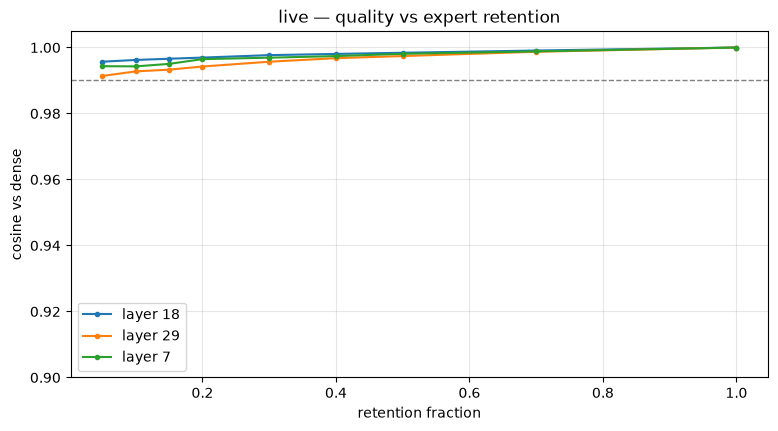

  0%|          | 0/306 [00:00<?, ?unit/s]


ran 306 units in 202.7 min


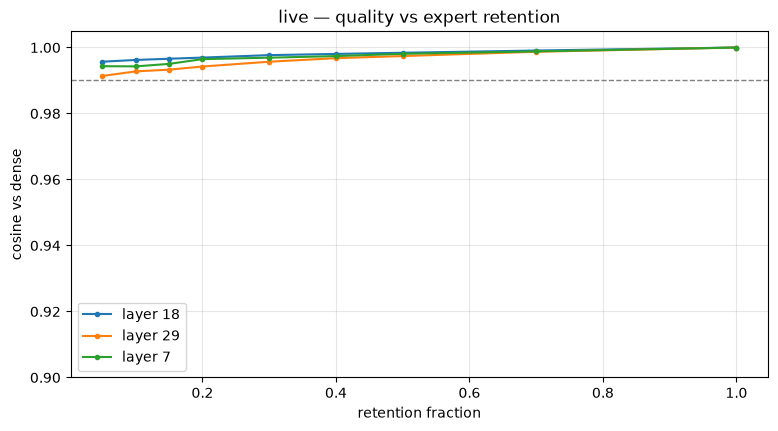

In [8]:
import csv, time, statistics
from collections import defaultdict
import matplotlib.pyplot as plt
from IPython.display import display, update_display
from tqdm.auto import tqdm
from src.oracle import oracle_multi_token

records = []
unit_times = []
fig, ax = plt.subplots(figsize=(9, 4.5)); plt.ioff()
h = display(fig, display_id="m1_live_plot")

def redraw(recs):
    ax.clear()
    by = defaultdict(lambda: defaultdict(list))
    for layer, cat, frac, cos, t1, kl in recs:
        by[layer][frac].append(cos)
    for layer, d in sorted(by.items()):
        xs = sorted(d)
        ax.plot(xs, [sum(d[x])/len(d[x]) for x in xs], marker="o", ms=3,
                label=f"layer {layer.split('.')[-1]}")
    ax.axhline(0.99, ls="--", c="gray", lw=1); ax.set_ylim(0.90, 1.005)
    ax.set_xlabel("retention fraction"); ax.set_ylabel("cosine vs dense")
    ax.set_title("live — quality vs expert retention"); ax.legend(); ax.grid(alpha=0.3)
    update_display(fig, display_id="m1_live_plot")

pbar = tqdm(todo, unit="unit")
for i, (layer, cat, prompt) in enumerate(pbar):
    t0 = time.time()
    results = oracle_multi_token(model, tokenizer, prompt, layer, FRACTIONS,
                                 group_size=GROUP_SIZE, score_mode=SCORE_MODE,
                                 max_positions=POSITIONS)
    with open(OUT_CSV, "a", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        if f.tell() == 0:
            w.writerow(["category","prompt","layer","retain_fraction","score_mode",
                        "cosine","top1_match","kl","n_positions"])
        for r in results:
            for c, t1, kl in zip(r["cosines"], r["top1"], r["kl"]):
                w.writerow([cat, prompt[:60], layer, r["retain_fraction"],
                            SCORE_MODE, f"{c:.4f}", t1, f"{kl:.4f}", len(r["cosines"])])
                records.append((layer, cat, r["retain_fraction"], c, t1, kl))
    unit_times.append(time.time() - t0)
    pbar.set_postfix_str(f"ETA {statistics.mean(unit_times)*(len(todo)-i-1)/60:.0f} min")
    if (i + 1) % 5 == 0 or i == len(todo) - 1:
        redraw(records)
pbar.close()
redraw(records)
print(f"\nran {len(todo)} units in {sum(unit_times)/60:.1f} min")

**What just happened:** every remaining unit was measured and appended to the CSV — the data is safe on disk. Next: read the CSV back and compute statistics.

## Step 7 — Summary table

Mean ± std of logit cosine and top-1 agreement per retention level, across ALL
measured units in the CSV (not just this session — re-runnable anytime).

In [9]:
import csv, statistics
from collections import defaultdict

with open(OUT_CSV, encoding="utf-8") as f:
    rows = list(csv.DictReader(f))
print(f"rows in CSV: {len(rows):,}\n")

by_cos, by_t1 = defaultdict(list), defaultdict(list)
for r in rows:
    frac = float(r["retain_fraction"])
    by_cos[frac].append(float(r["cosine"]))
    by_t1[frac].append(int(r["top1_match"]))

print(f"{'retain':>7} | {'n':>6} | {'cosine mean ± std':>19} | {'top1':>5}")
print("-" * 52)
for frac in sorted(by_cos, reverse=True):
    cs, t1s = by_cos[frac], by_t1[frac]
    sd = statistics.stdev(cs) if len(cs) > 1 else 0.0
    print(f"{frac:>7.2f} | {len(cs):>6} | {sum(cs)/len(cs):>10.4f} ± {sd:.4f} | "
          f"{sum(t1s)/len(t1s):>5.2f}")

rows in CSV: 21,843

 retain |      n |   cosine mean ± std |  top1
----------------------------------------------------
   1.00 |   2427 |     1.0000 ± 0.0000 |  1.00
   0.70 |   2427 |     0.9989 ± 0.0054 |  0.96
   0.50 |   2427 |     0.9980 ± 0.0092 |  0.95
   0.40 |   2427 |     0.9974 ± 0.0115 |  0.95
   0.30 |   2427 |     0.9968 ± 0.0129 |  0.94
   0.20 |   2427 |     0.9959 ± 0.0149 |  0.93
   0.15 |   2427 |     0.9950 ± 0.0281 |  0.93
   0.10 |   2427 |     0.9944 ± 0.0322 |  0.93
   0.05 |   2427 |     0.9938 ± 0.0269 |  0.92


**What just happened:** the statistics table is computed. Next: apply the blueprint's decision rule to the numbers.

## Step 8 — The §14 verdict

Blueprint rule: if ~30% of experts preserve logits (cosine ≥ 0.995, top-1 ≥ 0.9)
→ continue. 30–50% → investigate. >60–70% → pivot.

In [10]:
cat30 = defaultdict(list)
for r in rows:
    if round(float(r["retain_fraction"]), 2) == 0.30:
        cat30[r["category"]].append(float(r["cosine"]))

print("per-category mean cosine @30% retention:")
for cat, cs in sorted(cat30.items(), key=lambda kv: -len(kv[1])):
    print(f"  {cat:22s} {sum(cs)/len(cs):.4f}  (n={len(cs)})")

c30 = sum(by_cos[0.3])/len(by_cos[0.3]); t30 = sum(by_t1[0.3])/len(by_t1[0.3])
c20 = sum(by_cos[0.2])/len(by_cos[0.2]); t20 = sum(by_t1[0.2])/len(by_t1[0.2])
print(f"\n§14 gate: cosine@30%={c30:.4f} top1@30%={t30:.2f}  |  "
      f"cosine@20%={c20:.4f} top1@20%={t20:.2f}")
if c30 > 0.995 and t30 > 0.9:
    print("-> STRONG signal: 30% of experts preserve logits. Continue to router (M4).")
elif c30 > 0.98:
    print("-> INTERESTING: try neuron clustering (M3) before deciding.")
elif c30 > 0.9:
    print("-> WEAK: more than 30% required; broaden prompts before pivoting.")
else:
    print("-> FAILURE zone: quality collapses well above 30% (§55).")

per-category mean cosine @30% retention:
  math_gen               0.9960  (n=288)
  coding                 0.9930  (n=144)
  debugging              0.9977  (n=144)
  concurrency            0.9970  (n=144)
  security               0.9983  (n=144)
  testing                0.9988  (n=144)
  performance            0.9983  (n=144)
  code_review            0.9983  (n=144)
  api_system_design      0.9984  (n=144)
  devops_cloud           0.9962  (n=144)
  math                   0.9973  (n=144)
  reasoning              0.9905  (n=144)
  long_context           0.9978  (n=144)
  instruction_following  0.9954  (n=144)
  writing                0.9982  (n=138)
  general_knowledge      0.9978  (n=129)

§14 gate: cosine@30%=0.9968 top1@30%=0.94  |  cosine@20%=0.9959 top1@20%=0.93
-> STRONG signal: 30% of experts preserve logits. Continue to router (M4).


**What just happened:** the decision rule was applied to the data — the printed verdict is the experiment's conclusion. Next: publication-style plots (optional).

## Step 9 — Plots

Left: quality-vs-retention per layer. Right: per-category robustness at 30%.

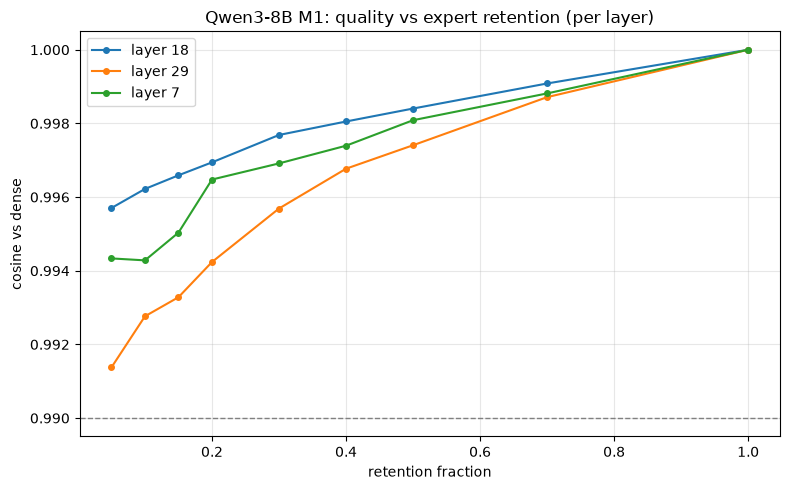

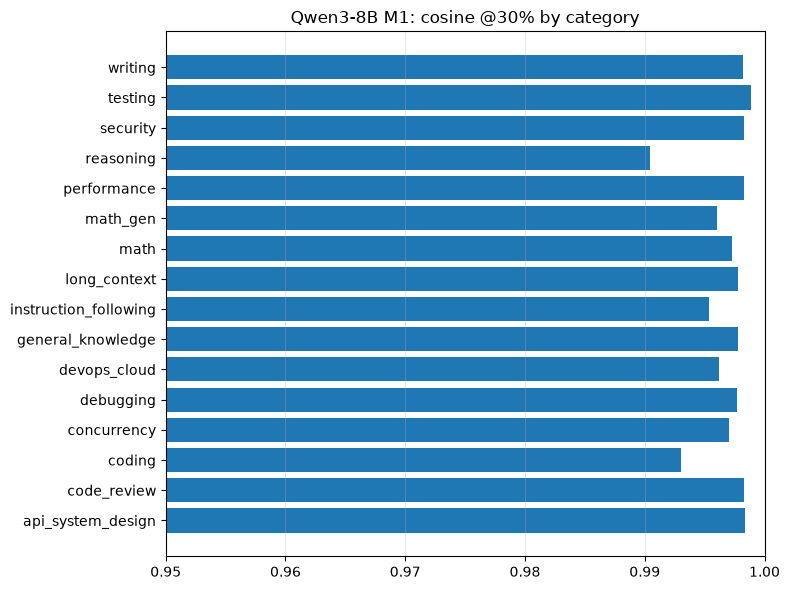

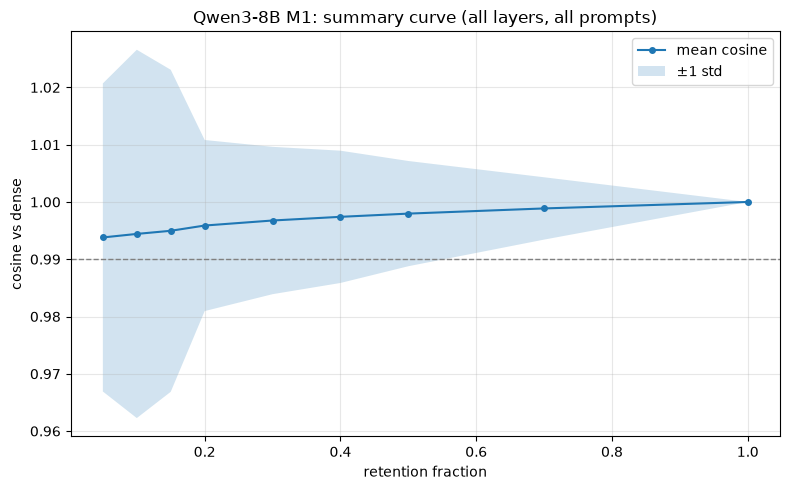

saved: e:\Project\SliceWeave\Qwen3-8B_Results\results\m1_oracle_sparsity\plots\m1_quality_vs_retention.png  (67 KB)
saved: e:\Project\SliceWeave\Qwen3-8B_Results\results\m1_oracle_sparsity\plots\m1_category_robustness_30pct.png  (54 KB)
saved: e:\Project\SliceWeave\Qwen3-8B_Results\results\m1_oracle_sparsity\plots\m1_summary_curve.png  (48 KB)


In [12]:
# M1 plots — regenerate ALL THREE from the CSV on disk (4B naming convention).
# Reading the CSV fresh makes this cell deterministic and re-runnable.
import csv as _csv, statistics
import matplotlib.pyplot as plt
from collections import defaultdict

# tag from the bundle that owns OUT_CSV (MODEL_ID may have been overwritten by
# the Step-2 knobs cell, which still hard-codes the 4B id)
_m1_tag = ("Qwen3-8B" if "Qwen3-8B_Results" in str(OUT_CSV)
           else "Qwen3-4B" if "Qwen3-4B_Results" in str(OUT_CSV)
           else "Qwen3")

by_layer = defaultdict(lambda: defaultdict(list))   # layer -> frac -> [cosine]
cat30 = defaultdict(list)                           # category -> [cosine @30%]
all_by_frac = defaultdict(list)                     # frac -> [cosine]
with open(OUT_CSV, encoding="utf-8") as f:
    for r in _csv.DictReader(f):
        frac = float(r["retain_fraction"]); cos = float(r["cosine"])
        by_layer[r["layer"]].setdefault(frac, []).append(cos)
        all_by_frac[frac].append(cos)
        if round(frac, 2) == 0.30:
            cat30[r["category"]].append(cos)

PLOT_DIR.mkdir(parents=True, exist_ok=True)

# 1) m1_quality_vs_retention.png — per-layer mean cosine vs retention
figA, axA = plt.subplots(figsize=(8, 5))
for layer, d in sorted(by_layer.items()):
    xs = sorted(d)
    axA.plot(xs, [sum(d[x])/len(d[x]) for x in xs], marker="o", ms=4,
             label=f"layer {layer.split('.')[-1]}")
axA.axhline(0.99, ls="--", c="gray", lw=1)
axA.set_xlabel("retention fraction"); axA.set_ylabel("cosine vs dense")
axA.set_title(f"{_m1_tag} M1: quality vs expert retention (per layer)")
axA.legend(); axA.grid(alpha=0.3)
figA.tight_layout()
pA = PLOT_DIR / "m1_quality_vs_retention.png"
figA.savefig(pA, dpi=150)

# 2) m1_category_robustness_30pct.png — per-category barh @30%
cats = sorted(cat30)
figB, axB = plt.subplots(figsize=(8, 6))
axB.barh(cats, [sum(cat30[c])/len(cat30[c]) for c in cats])
axB.set_xlim(0.95, 1.0); axB.set_title(f"{_m1_tag} M1: cosine @30% by category")
axB.grid(alpha=0.3, axis="x")
figB.tight_layout()
pB = PLOT_DIR / "m1_category_robustness_30pct.png"
figB.savefig(pB, dpi=150)

# 3) m1_summary_curve.png — overall mean ± std vs retention
xs = sorted(all_by_frac)
means = [sum(all_by_frac[x])/len(all_by_frac[x]) for x in xs]
sds = [ (statistics.stdev(all_by_frac[x]) if len(all_by_frac[x]) > 1 else 0.0) for x in xs ]
figC, axC = plt.subplots(figsize=(8, 5))
axC.plot(xs, means, marker="o", ms=4, label="mean cosine")
axC.fill_between(xs, [m-s for m, s in zip(means, sds)], [m+s for m, s in zip(means, sds)], alpha=0.2, label="±1 std")
axC.axhline(0.99, ls="--", c="gray", lw=1)
axC.set_xlabel("retention fraction"); axC.set_ylabel("cosine vs dense")
axC.set_title(f"{_m1_tag} M1: summary curve (all layers, all prompts)")
axC.legend(); axC.grid(alpha=0.3)
figC.tight_layout()
pC = PLOT_DIR / "m1_summary_curve.png"
figC.savefig(pC, dpi=150)

plt.show(figA)
for p in (pA, pB, pC):
    print(f"saved: {p}  ({p.stat().st_size/1024:.0f} KB)")


**What just happened:** Milestone 1 is complete and visualized. ✅ GATE PASSED (STRONG signal — cosine@30%=0.9968, top1@30%=0.94, all 3 layers; repaired CSV, 21,843 rows).

## What happens after this milestone

➡️ **Continue in `notebooks/task_specialization.ipynb`** (Milestone 2: do different tasks use different experts?)

| Next milestone | What it does | Uses what from here |
|---|---|---|
| **M2** task specialization → `notebooks/task_specialization.ipynb` | do different tasks use different experts? | the same capture machinery |
| **M3** clustering (`04_cluster_neurons.py`) | group co-activating neurons, reorder FFN exactly | z-activation statistics |
| **M4** token router (`05_centroid_router.py`) | predict important experts cheaply from the hidden state | the oracle rankings as ground truth |

## Where the data lives

- `Qwen3-8B_Results/results/m1_oracle_sparsity/csv/oracle_ffn.csv` — every measurement
  (one row = one masked token; 306 units complete; pre-dedup original in
  `Qwen3-8B_Results/results/_archive/`)
- This notebook is safe to close anytime; step 6 resumes from the CSV on reopen

**Run order recap:** cells 2→3 (instant) → 4 (model, ~3 min on 8B) → 5→6 (instant;
step 6 prints 0 to run when the sweep is complete) → 7→8 (the verdict) → 9 (plots).
Run All works too.
